# 함정 2. 내림(floor)은 반올림 오차를 4배로 만든다

같은 입력과 스텝에서 반올림 방식만 바꾼다. 클리핑이 없는 영역의 오차 모멘트, 보정 방법 두 가지, 8-bit full range의 클리핑 포함 MSE를 비교한다. nearest는 `floor(x + 0.5)`인 half-up 규칙이다.

시드는 0 하나이며, 환경 표의 실행 시간은 마지막 셀에서 갱신된다. 설계와 기대값: [학습 가이드](../docs/README.md#함정-2-내림floor은-반올림-오차를-4배로-만든다).


In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RESULTS = ROOT / "runs" / "m1"
FIGURES = ROOT / "docs" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(RESULTS / ".matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls"})
RUN_INFO = {"seed": SEED, "seeds": 1, "python": platform.python_version(), "torch": torch.__version__, "device": DEVICE, "integration_device": "cpu",
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "runtime_seconds": None}
STARTED = time.monotonic()
run_display = display(RUN_INFO, display_id=True)


{'seed': 0,
 'seeds': 1,
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'integration_device': 'cpu',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.521}

In [2]:
from quant_pitfalls.analysis import expected_mse, optimal_clip
from quant_pitfalls.quant.rounding import round_floor, round_nearest
from quant_pitfalls.quant.uniform import UniformSpec, fake_quant

x = torch.rand(1_000_000, generator=generator, device=DEVICE, dtype=torch.float64) * 100
errors = {"Nearest": round_nearest(x) - x, "Floor": round_floor(x) - x,
          "Half-LSB before floor": round_floor(x + 0.5) - x, "Bias correction after floor": round_floor(x) + 0.5 - x}
moments = []
print("Method | mean error | MSE | mean error in sums of 100 terms")
for label, error in errors.items():
    row = {"method": label, "mean": float(error.mean()), "mse": float(error.square().mean()),
           "sum_100_mean": float(error.reshape(-1, 100).sum(dim=1).mean())}
    moments.append(row)
    print(f"{label:27s} | {row['mean']:.6f} | {row['mse']:.6f} | {row['sum_100_mean']:.6f}")
unclipped_ratio = moments[1]["mse"] / moments[0]["mse"]
print(f"Unclipped floor/nearest MSE ratio: {unclipped_ratio:.5f}")


Method | mean error | MSE | mean error in sums of 100 terms
Nearest                     | -0.000038 | 0.083433 | -0.003831
Floor                       | -0.500384 | 0.333622 | -50.038431
Half-LSB before floor       | -0.000038 | 0.083433 | -0.003831
Bias correction after floor | -0.000384 | 0.083238 | -0.038431
Unclipped floor/nearest MSE ratio: 3.99867


## 8-bit full range에서 클리핑까지 포함한 비교

분포와 비트 수를 고정한다. 동일한 4σ 클립에서 두 반올림 방식을 비교한 뒤, 각 방식의 최적 클립을 따로 찾는다. 클리핑 오차가 더해져 전체 MSE 비는 4보다 작아진다.

위의 사후 bias 보정은 오차 수준의 비교이며 출력 격자를 반 스텝 옮긴다. 실제 다음 레이어의 bias 보정은 아래의 학습된 레이어 비교에서 다룬다.


Mode | fixed MSE | optimal alpha | optimal MSE
nearest | 8.8324527e-05 | 3.91184 | 8.7705039e-05
floor   | 0.00033668812 | 3.59850 | 0.00030240617
Floor/nearest ratios: {'fixed': 3.8119435980931873, 'optimal': 3.447990817653822}


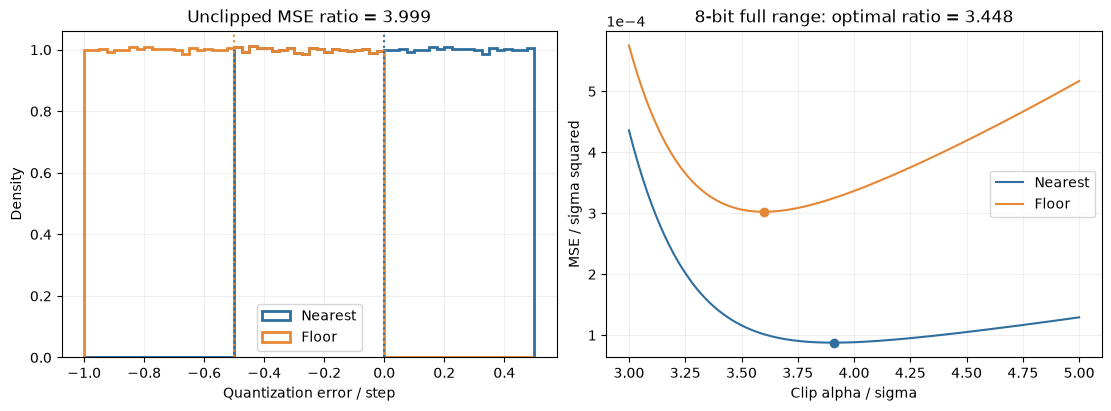

In [3]:
rows = []
curves = {}
for mode in ["nearest", "floor"]:
    spec = UniformSpec(8, narrow_range=False, rounding=mode)
    make_quantizer = lambda alpha, spec=spec: (lambda t: fake_quant(t, alpha, spec))
    alpha, mse = optimal_clip(make_quantizer, "gaussian", 3.0, 6.0)
    rows.append({"rounding": mode, "fixed_alpha": 4.0, "fixed_mse": expected_mse(make_quantizer(4), "gaussian"),
                 "optimal_alpha": alpha, "optimal_mse": mse})
    grid = np.linspace(3, 5, 101)
    curves[mode] = [expected_mse(make_quantizer(float(a)), "gaussian") for a in grid]
ratios = {"fixed": rows[1]["fixed_mse"] / rows[0]["fixed_mse"], "optimal": rows[1]["optimal_mse"] / rows[0]["optimal_mse"]}
print("Mode | fixed MSE | optimal alpha | optimal MSE")
for row in rows:
    print(f"{row['rounding']:7s} | {row['fixed_mse']:.8g} | {row['optimal_alpha']:.5f} | {row['optimal_mse']:.8g}")
print("Floor/nearest ratios:", ratios)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
bins = np.linspace(-1, 0.5, 61)
for label, color in [("Nearest", "#2E6F9E"), ("Floor", "#E68735")]:
    axes[0].hist(errors[label].cpu().numpy(), bins=bins, density=True, histtype="step", linewidth=2, label=label, color=color)
axes[0].axvline(0, color="#2E6F9E", linestyle=":")
axes[0].axvline(-0.5, color="#E68735", linestyle=":")
axes[0].set(xlabel="Quantization error / step", ylabel="Density", title=f"Unclipped MSE ratio = {unclipped_ratio:.3f}")
axes[0].legend()
for row, color in zip(rows, ["#2E6F9E", "#E68735"]):
    mode = row["rounding"]
    axes[1].plot(grid, curves[mode], label=mode.title(), color=color)
    axes[1].plot(row["optimal_alpha"], row["optimal_mse"], "o", color=color)
axes[1].set(xlabel="Clip alpha / sigma", ylabel="MSE / sigma squared", title=f"8-bit full range: optimal ratio = {ratios['optimal']:.3f}")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(FIGURES / "02_floor-rounding.svg", metadata={"Date": None})
fig.savefig(RESULTS / "02_floor-rounding.png", dpi=140)
plt.show()
report = {"moments": moments, "unclipped_ratio": unclipped_ratio, "clipping": rows, "ratios": ratios}


In [4]:
if DEVICE == "cuda":
    torch.cuda.synchronize()
report["run"] = {**RUN_INFO, "runtime_seconds": round(time.monotonic() - STARTED, 3)}
(RESULTS / "02_floor-rounding.json").write_text(json.dumps(report, indent=2) + "\n")
run_display.update(report["run"])
print("Saved results: runs/m1/02_floor-rounding.json")


Saved results: runs/m1/02_floor-rounding.json


## 실제 레이어의 평균 이동과 bias 보정

학습된 MobileNetV2의 첫 convolution 입력에서 nearest/floor와 두 보정 방식의 평균 이동·MSE를 비교한다. 시드 0·1·2의 측정 기록을 읽으며, 보정에 쓴 입력과 평가 입력을 구분한다.

기본 재현 명령은 저장소의 측정 기록을 사용한다. 새로운 학습 결과를 만들려면 [재현 방법](../docs/reproduction.md)의 체크포인트·학습 모드를 참고한다.


In [5]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 0.571,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


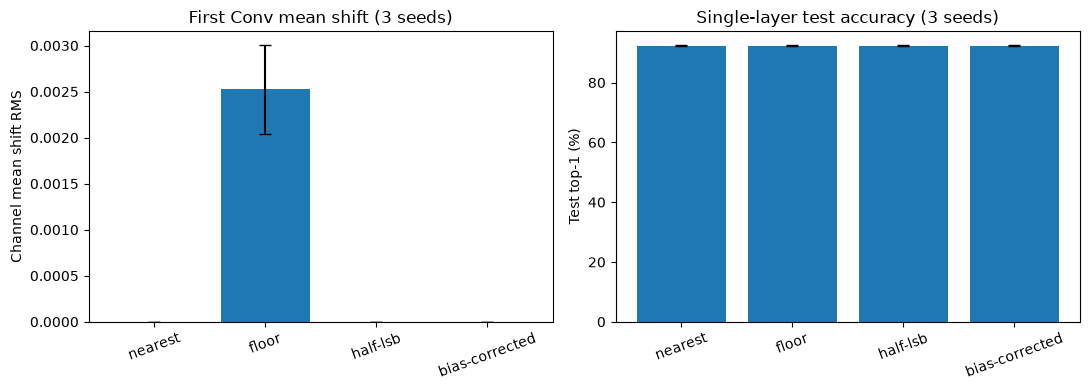

In [6]:
if READY:
    rows=REPORT['floor_bias']['rows']
    methods=('nearest','floor','half-lsb','bias-corrected')
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,key,title in zip(axes,('output_channel_mean_shift_rms','top1'),('First Conv mean shift','Single-layer test accuracy')):
        values=np.array([[r[key] for r in rows if r['method']==method] for method in methods])
        ax.bar(methods,values.mean(1),yerr=values.std(1,ddof=1),capsize=4)
        ax.set_title(title+' (3 seeds)')
        ax.tick_params(axis='x',rotation=20)
    axes[0].set_ylabel('Channel mean shift RMS')
    axes[1].set_ylabel('Test top-1 (%)')
    fig.tight_layout()
    save_figure(fig,'02_floor-layer-bias')

In [7]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

스텝을 1로 고정하고 −1.5, −0.5, 0.5, 1.5의 nearest·floor 코드를 직접 계산해 보자. half-up 규칙이 음수 tie에서 어떻게 작동하는지 테스트와 비교하자.
